<div class='alert alert-block alert-info'>
<h1 align='center'>Multiclass classification</h1>
<h2 align='center'>Softmax</h2>
<h3 align='center'>Iris dataset</h3>
</div>

# Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score

# Load Dataset

In [ ]:
dataset=load_iris()
print(dataset.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [ ]:
x,y=load_iris(return_X_y=True) 
df=pd.DataFrame(x, columns=dataset.feature_names)
df['species']=y
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


# EDA

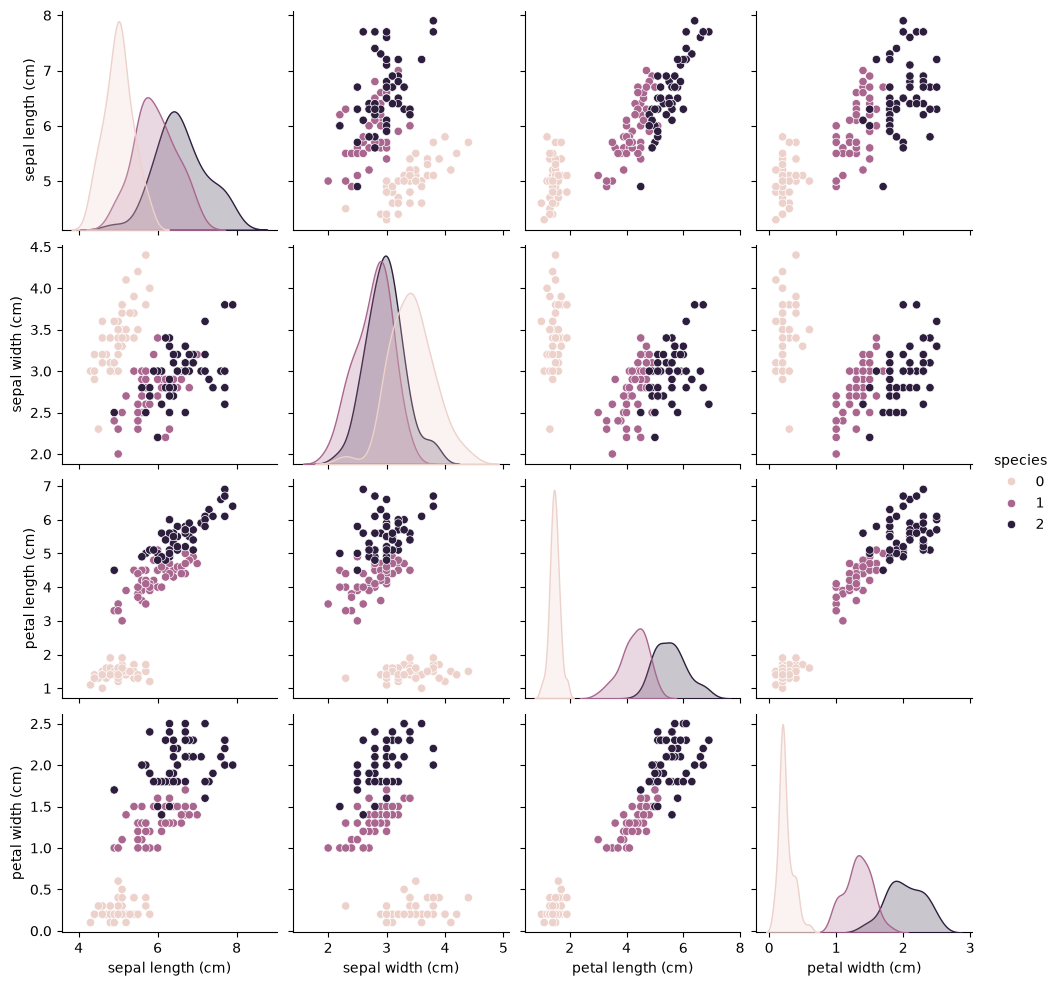

In [ ]:
sns.pairplot(df, hue='species')
plt.show()

# Split Train Test data

In [ ]:
x_train, x_test, y_train, y_test=train_test_split(x, y, test_size=0.2, random_state=42)

# Standardization

In [ ]:
sc=StandardScaler()
x_train_s=sc.fit_transform(x_train)

# Required Functions

In [ ]:
def augmentation(arr):
    return np.hstack((np.ones((len(arr),1)), arr))

In [ ]:
def one_hot_encoding(arr):
    return label_binarize(arr, classes=np.unique(arr))

In [ ]:
def softmax(x_augmented,w):
    arr=x_augmented @ w
    prob_sum=np.sum(np.exp(arr),axis=1, keepdims=True)
    return  np.exp(arr)/prob_sum

In [ ]:
def gradient_descent(x_augmented, y_, y_one_hot):
    return (x_augmented.T @ (y_-y_one_hot))/len(x_augmented)

In [ ]:
def BCE(y_one_hot, s):
    return -np.mean(np.sum(y_one_hot*np.log(s), axis=1))

# Initializing

In [ ]:
x_augment=augmentation(x_train_s)
y_one_hot=one_hot_encoding(y_train)

N_epoch=1000
learning_rate=0.1

np.random.seed(42)
n_features=x_augment.shape[1]
n_classes=len(np.unique(y_train))
w=np.random.rand(n_features, n_classes)

# Training

In [ ]:
loss_hist=[]
for epoch in range(N_epoch):

    y_hat=softmax(x_augment, w)

    grad=gradient_descent(x_augment, y_hat, y_one_hot)
    w-=learning_rate*grad

    loss=BCE(y_one_hot , y_hat)
    loss_hist.append(loss)

    print(f'Epoch: {epoch}\t Loss: {loss:.3f}, w: {w.T[0]}')

Epoch: 0	 Loss: 2.041, w: [0.37565392 0.55736528 0.09200266 0.65611396 0.78239634]
Epoch: 1	 Loss: 1.885, w: [0.37837619 0.51814346 0.12532327 0.6062816  0.73443871]
Epoch: 2	 Loss: 1.742, w: [0.38253126 0.48100923 0.15798601 0.55859862 0.68858518]
Epoch: 3	 Loss: 1.610, w: [0.38789878 0.44594128 0.18992395 0.51306412 0.64482891]
Epoch: 4	 Loss: 1.489, w: [0.39422831 0.41289535 0.2210627  0.46966616 0.60315383]
Epoch: 5	 Loss: 1.379, w: [0.40125505 0.38181798 0.25132071 0.42839241 0.56354471]
Epoch: 6	 Loss: 1.279, w: [0.40871481 0.35265525 0.28061111 0.38923517 0.5259916 ]
Epoch: 7	 Loss: 1.188, w: [0.4163574  0.32535554 0.30884589 0.35219016 0.49048831]
Epoch: 8	 Loss: 1.107, w: [0.42395821 0.2998671  0.33594234 0.31725045 0.4570262 ]
Epoch: 9	 Loss: 1.034, w: [0.4313271  0.2761331  0.36183077 0.28439808 0.42558612]
Epoch: 10	 Loss: 0.970, w: [0.43831408 0.25408678 0.38646167 0.25359657 0.3961311 ]
Epoch: 11	 Loss: 0.913, w: [0.44481108 0.23364869 0.40981072 0.2247865  0.36860214]
Ep

Epoch: 197	 Loss: 0.291, w: [ 0.31551499 -0.31040617  1.17963681 -0.66504331 -0.46081132]
Epoch: 198	 Loss: 0.290, w: [ 0.3148994  -0.3115326   1.18105109 -0.66701543 -0.46261754]
Epoch: 199	 Loss: 0.290, w: [ 0.31428723 -0.31265554  1.18245916 -0.66898145 -0.46441821]
Epoch: 200	 Loss: 0.289, w: [ 0.31367846 -0.31377502  1.18386109 -0.67094144 -0.46621338]
Epoch: 201	 Loss: 0.289, w: [ 0.31307305 -0.31489107  1.18525693 -0.67289544 -0.4680031 ]
Epoch: 202	 Loss: 0.288, w: [ 0.31247099 -0.31600372  1.18664676 -0.67484351 -0.46978742]
Epoch: 203	 Loss: 0.288, w: [ 0.31187225 -0.31711299  1.18803063 -0.67678569 -0.47156638]
Epoch: 204	 Loss: 0.287, w: [ 0.3112768  -0.31821892  1.18940861 -0.67872206 -0.47334004]
Epoch: 205	 Loss: 0.287, w: [ 0.31068462 -0.31932154  1.19078076 -0.68065264 -0.47510845]
Epoch: 206	 Loss: 0.286, w: [ 0.31009569 -0.32042086  1.19214713 -0.6825775  -0.47687164]
Epoch: 207	 Loss: 0.286, w: [ 0.30950997 -0.32151693  1.19350779 -0.68449668 -0.47862968]
Epoch: 208

# Save Model Weights

In [ ]:
np.savetxt('Model weights.txt',w)

# Load Model weights

In [ ]:
model=np.loadtxt('Model weights.txt')

# Evaluation Metrics

In [ ]:
x_test_s=sc.transform(x_test)
x_augmente_t=augmentation(x_test_s)
y_hat=softmax(x_augmente_t, model)
y_pre=y_hat.argmax(axis=1).reshape(-1,1)

acc=accuracy_score(y_test, y_pre)
print(f'Accuracy of test data in this model is : {acc*100} %')

Accuracy of test data in this model is : 100.0 %


# Loss function graph

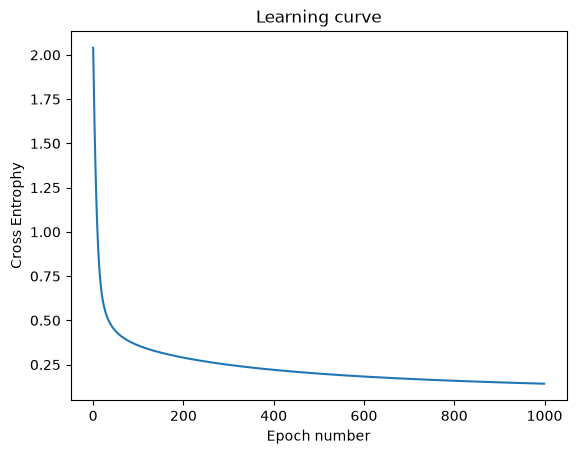

In [ ]:
plt.title('Learning curve')
plt.xlabel('Epoch number')
plt.ylabel('Cross Entrophy')
plt.plot(loss_hist)
plt.show()